# INF-8239 · Unidad 03 · Ejercicio 06
## VAE, evaluación y Model Card

Este cuaderno presenta los resultados persistidos por el entrenamiento reproducible, las figuras generadas y una interpretación limitada a las métricas realmente calculadas. Ejecute primero `uv run python scripts/train_ae_vae.py --epochs-ae 6 --epochs-vae 8` desde la raíz del proyecto.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "reports" / "training_metrics.json").exists():
    ROOT = ROOT.parent
metrics_path = ROOT / "reports" / "training_metrics.json"
if not metrics_path.exists():
    raise FileNotFoundError("No se encuentra reports/training_metrics.json; ejecute el entrenamiento desde la raíz del proyecto.")
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
experiment = metrics["experiment"]
training = metrics["training"]
evaluation = metrics["evaluation"]
print(f"Corrida UTC: {experiment['run_at_utc']} | Python {experiment['runtime']['python']} | TensorFlow {experiment['runtime']['tensorflow']}")
print(f"Datos: {experiment['train_samples']:,} entrenamiento; {experiment['test_samples']:,} prueba; semilla {experiment['seed']}; dispositivos {experiment['runtime']['devices']}")

Corrida UTC: 2026-10-10T17:55:23.332587+00:00 | Python 3.12.14 | TensorFlow 2.21.0
Datos: 60,000 entrenamiento; 10,000 prueba; semilla 42; dispositivos ['/physical_device:CPU:0']


In [2]:
ae = evaluation["ae"]
vae = evaluation["vae"]
display(Markdown(
    "| Modelo | MAE ↓ | MSE ↓ | BCE/reconstrucción por imagen | KL por imagen |\n"
    "|---|---:|---:|---:|---:|\n"
    f"| AE | {ae['mae']:.4f} | {ae['mse']:.4f} | {ae['binary_crossentropy_sum_per_image']:.2f} | — |\n"
    f"| VAE (media posterior) | {vae['mae']:.4f} | {vae['mse']:.4f} | {vae['reconstruction_loss_sum_per_image']:.2f} | {vae['kl_divergence_per_image']:.2f} |\n\n"
    f"VAE: objetivo reconstrucción + KL = **{vae['elbo_loss_per_image']:.2f} por imagen**. "
    "La reconstrucción del VAE usa la media posterior de forma determinista, no una estimación Monte Carlo del ELBO. "
    "MAE/MSE son medias por píxel; la BCE reportada se suma sobre píxeles."
))
print(f"Historial final AE: loss={training['ae_history']['loss'][-1]:.4f}, val_loss={training['ae_history']['val_loss'][-1]:.4f}")
print(f"Historial final VAE: loss={training['vae_history']['loss'][-1]:.2f}, reconstruction={training['vae_history']['reconstruction'][-1]:.2f}, KL={training['vae_history']['kl'][-1]:.2f}")

| Modelo | MAE ↓ | MSE ↓ | BCE/reconstrucción por imagen | KL por imagen |
|---|---:|---:|---:|---:|
| AE | 0.0820 | 0.0203 | 240.55 | — |
| VAE (media posterior) | 0.1086 | 0.0330 | 266.99 | 6.30 |

VAE: objetivo reconstrucción + KL = **273.29 por imagen**. La reconstrucción del VAE usa la media posterior de forma determinista, no una estimación Monte Carlo del ELBO. MAE/MSE son medias por píxel; la BCE reportada se suma sobre píxeles.

Historial final AE: loss=0.3060, val_loss=0.3071
Historial final VAE: loss=273.58, reconstruction=267.32, KL=6.26


### Reconstrucción y generación
El panel presenta, en orden, originales, reconstrucción AE, reconstrucción VAE y muestras generadas. La segunda figura interpola entre dos puntos fijados manualmente del espacio latente.

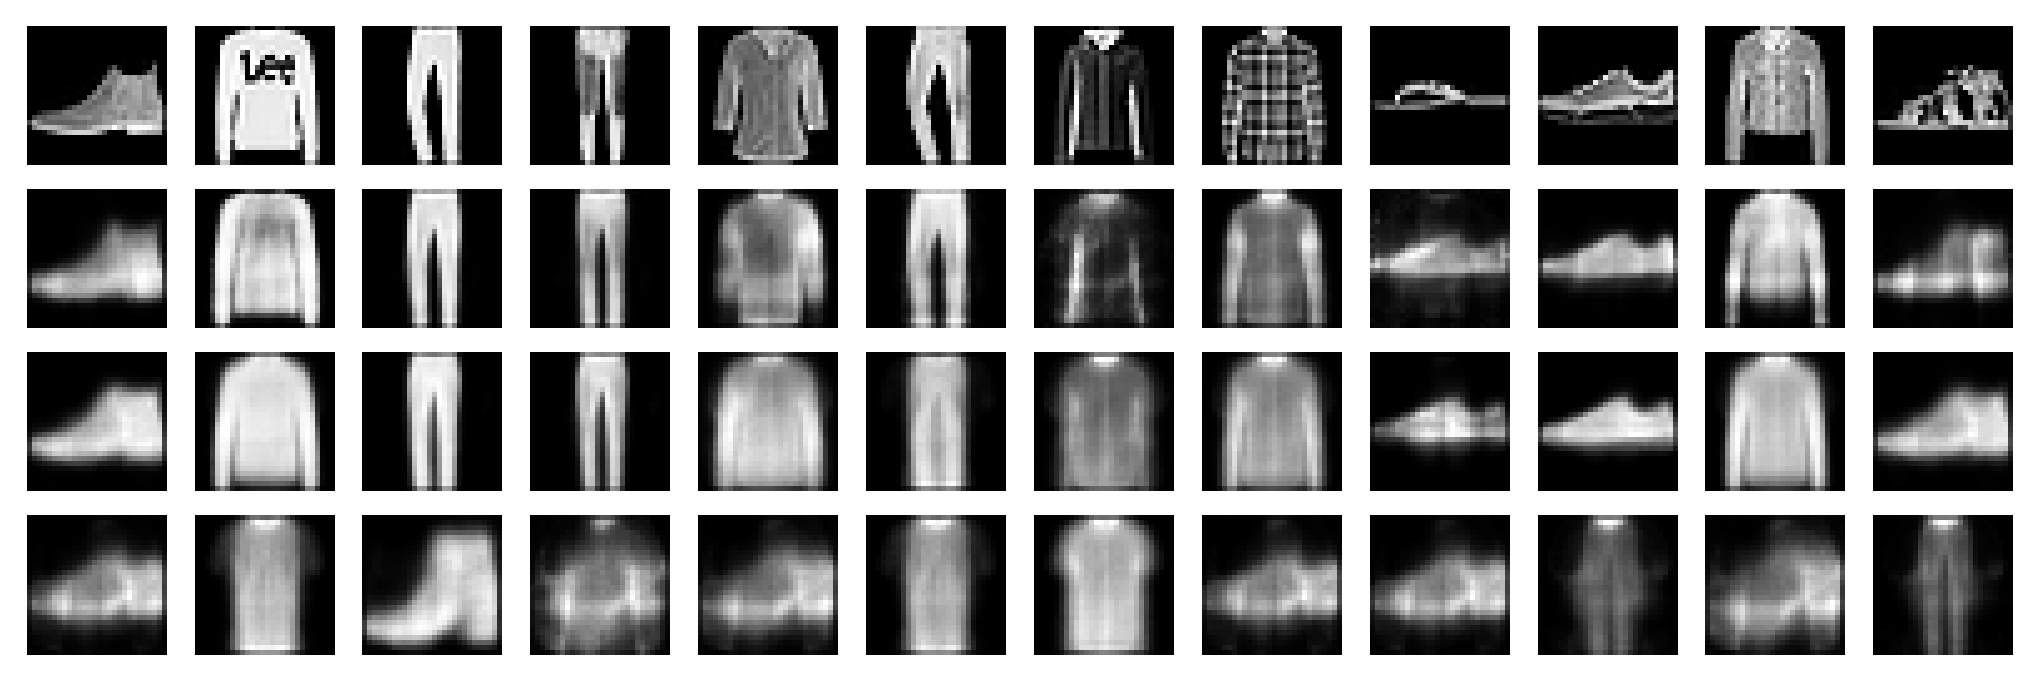

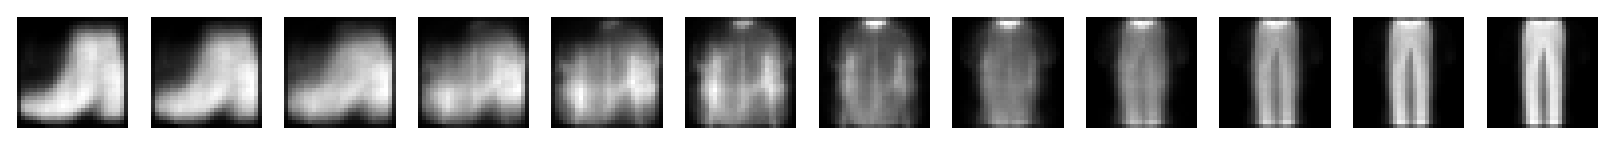

In [3]:
display(Markdown("### Reconstrucción y generación\nEl panel presenta, en orden, originales, reconstrucción AE, reconstrucción VAE y muestras generadas. La segunda figura interpola entre dos puntos fijados manualmente del espacio latente."))
display(Image(filename=str(ROOT / "reports" / "ae_vae_panel.png")))
display(Image(filename=str(ROOT / "reports" / "interpolation.png")))

In [4]:
generation = evaluation["generation"]
models = metrics["models"]
display(Markdown(
    "### Diversidad, proximidad y costo\n"
    f"- MAE media entre pares de muestras generadas: **{generation['mean_pairwise_pixel_mae']:.4f}** "
    f"(estimada con {generation['pairwise_pixel_mae_pairs']:,} pares).\n"
    f"- MAE al vecino más cercano medio: **{generation['mean_nearest_reference_subset_pixel_mae']:.4f}** "
    f"(comparación con {generation['reference_samples']:,} imágenes de referencia).\n"
    f"- Tiempo de ajuste AE/VAE: **{training['ae_seconds']:.2f}/{training['vae_seconds']:.2f} s**; "
    f"parámetros AE/VAE: **{models['ae_parameters']:,}/{models['vae_total_parameters']:,}**.\n"
    f"- Huella teórica float32 de pesos AE/VAE: **{models['ae_float32_weights_bytes']:,}/"
    f"{models['vae_float32_weights_bytes']:,} bytes**. Es una estimación del almacenamiento de pesos, "
    "no una medida del pico de RAM del proceso."
))

### Diversidad, proximidad y costo
- MAE media entre pares de muestras generadas: **0.1567** (estimada con 4,096 pares).
- MAE al vecino más cercano medio: **0.0768** (comparación con 1,000 imágenes de referencia).
- Tiempo de ajuste AE/VAE: **14.08/27.78 s**; parámetros AE/VAE: **25,888/202,516**.
- Huella teórica float32 de pesos AE/VAE: **103,552/810,064 bytes**. Es una estimación del almacenamiento de pesos, no una medida del pico de RAM del proceso.

## Conclusión y límites

En esta corrida el AE obtuvo menor MAE/MSE en prueba que el VAE reconstruido con su media posterior. El VAE optimiza un objetivo distinto que incluye KL; no se deben comparar sus pérdidas como si fueran exactamente el mismo criterio. Las distancias calculadas están en espacio de píxeles y el vecino más cercano se busca solo en una muestra aleatoria de referencia: no miden calidad semántica, cobertura de clases ni garantizan privacidad. Los datos son Fashion-MNIST (imágenes en escala de grises de 28×28), el experimento usa una semilla y no mide intervalos de confianza o utilidad downstream.
